mnist vae

In [2]:
import torch
import torch.nn as nn

In [1]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

tf = transforms.ToTensor()  # pixels → [0, 1], shape (1, 28, 28)

train_set = datasets.MNIST('./data', train=True,  download=True, transform=tf)  # 60,000 images
test_set  = datasets.MNIST('./data', train=False, download=True, transform=tf)  # 10,000 images

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=128, shuffle=False)


100%|██████████| 9.91M/9.91M [00:00<00:00, 17.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 444kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.3MB/s]


In [3]:
class VAE(nn.Module):
	def __init__(self, emb_dim=400, z_dim=20):
		super().__init__()

		# MNIST image -> mix
		self.enc = nn.Sequential(
			nn.Linear(784, emb_dim),
			nn.ReLU()
		)
		# emb -> zdim means, stds
		self.mu = nn.Linear(emb_dim, z_dim)
		self.logvar = nn.Linear(emb_dim, z_dim)

		# rnd pnt in gaussian -> MNIST img
		self.dec = nn.Sequential(
			nn.Linear(z_dim, emb_dim),
			nn.ReLU(),
			nn.Linear(emb_dim, 784),
			nn.Sigmoid()
		)

	def forward(self, x):
		# cmpte embedding
		h = self.enc(x)
		mu = self.mu(h)
		logvar = self.logvar(h)

		# using these projected mu, logvar of the gaussian of this specific point in high dim space
		# we'll find a point on this gaussian
		z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

		# decode this randomized point of the gaussian
		mnist_out = self.dec(z)
		return mnist_out, mu, logvar

Loss function:

binary cross entropy. loss wants to make x = xhat obviously by lowering overall cross entropy
$$\text{BCE} = -\sum_{i=1}^{784} \Big[x_i \log \hat{x}_i + (1 - x_i)\log(1 - \hat{x}_i)\Big]$$

Derived not by me but $KL(\mathcal{Z} \| \mathcal{N}(0, 1))$
$$D_{KL} = -\frac{1}{2}\sum_{j=1}^{20}\Big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\Big)$$
$$\mathcal{L}_{\text{batch}} = \sum_{n=1}^{B}\big(\text{BCE}_n + D_{KL,n}\big)$$

In [4]:
def loss_fn(out, orig, mu, logvar):
	out = out.clamp(1e-7, 1-1e-7)
	bce = - torch.sum(orig * torch.log(out) + (1-orig) * torch.log(1-out))
	kld = -0.5 * torch.sum(1 + logvar - mu**2 - logvar.exp())
	return bce + kld

In [6]:
mymodel = VAE()
opt = torch.optim.Adam(mymodel.parameters())

lossi = []

for img, y in train_loader:
	x = img.flatten(2)
	out, mu, logvar = mymodel(x)
	loss = loss_fn(out, x, mu, logvar)
	
	opt.zero_grad()
	loss.backward()
	opt.step()

	lossi.append(loss.item())
print(loss.item())

11833.611328125


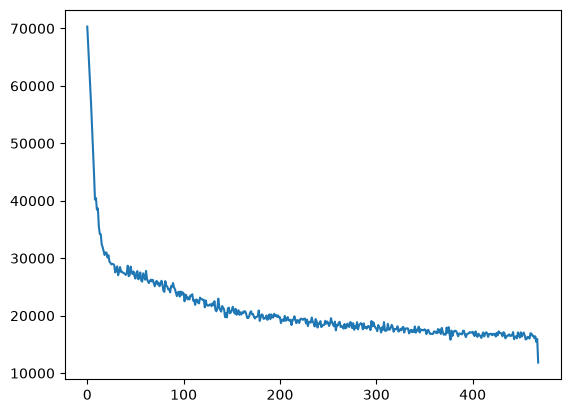

In [7]:
import matplotlib.pyplot as plt
plt.plot(lossi)

In [8]:
vlossi = []

mymodel.eval()
for img, y in test_loader:
	x = img.flatten(2)
	with torch.no_grad():
		out, mu, logvar = mymodel(x)
	loss = loss_fn(out, x, mu, logvar)
	vlossi.append(loss.item())
mymodel.train()

VAE(
  (enc): Sequential(
    (0): Linear(in_features=784, out_features=400, bias=True)
    (1): ReLU()
  )
  (mu): Linear(in_features=400, out_features=20, bias=True)
  (logvar): Linear(in_features=400, out_features=20, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=20, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=784, bias=True)
    (3): Sigmoid()
  )
)

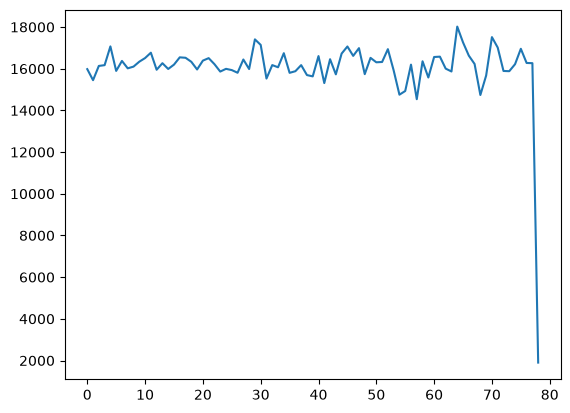

In [9]:
plt.plot(vlossi)